In [ ]:
# 1️⃣ IMPORT DES LIBRAIRIES
# ----------------------------------------------------------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Configuration des graphiques
plt.style.use('default')
sns.set_palette("husl")
%matplotlib inline

print("✅ Librairies importées avec succès !")

✅ Librairies importées avec succès !


## Analyse Rapide


In [ ]:
# 2️⃣ CHARGEMENT DU DATASET
# ----------------------------------------------------------------------------
# Charger le dataset preprocessé
df = pd.read_csv('electricity_fraud_features.csv')

print("\n" + "="*70)
print("📁 DATASET CHARGÉ")
print("="*70)
print(f"✅ Fichier : electricity_fraud_features.csv")
print(f"📊 Shape : {df.shape[0]:,} lignes × {df.shape[1]} colonnes")


📁 DATASET CHARGÉ
✅ Fichier : electricity_fraud_features.csv
📊 Shape : 42,372 lignes × 17 colonnes


In [ ]:
# 3️⃣ ANALYSE RAPIDE
# ----------------------------------------------------------------------------

# A) APERÇU DES DONNÉES
print("\n" + "="*70)
print("🔍 APERÇU DES PREMIÈRES LIGNES")
print("="*70)
print(df.head())



🔍 APERÇU DES PREMIÈRES LIGNES
                            CONS_NO  FLAG  mean_consumption  std_consumption  \
0  0387DD8A07E07FDA6271170F86AD9151     1          0.944130         3.094565   
1  01D6177B5D4FFE0CABA9EF17DAFC2B84     1          3.768801         6.666713   
2  4B75AC4F2D8434CFF62DB64D0BB43103     1          5.740000         9.368963   
3  B32AC8CC6D5D805AC053557AB05F5343     1          3.578627         7.943032   
4  EDFC78B07BA2908B3395C4EB2304665E     1         23.225967        49.519538   

   median_consumption  max_consumption        cv  q25      q75      iqr  \
0               0.000            18.29  3.277691  0.0   0.0000   0.0000   
1               0.550            44.57  1.768922  0.3   4.6775   4.3775   
2               1.875            79.71  1.632223  0.0   8.7150   8.7150   
3               0.000            40.98  2.219575  0.0   0.0000   0.0000   
4               0.000           399.40  2.132076  0.0  25.2175  25.2175   

   zero_days  zero_ratio     trend  n

In [ ]:
# B) INFORMATIONS GÉNÉRALES
print("\n" + "="*70)
print("📋 INFORMATIONS SUR LES COLONNES")
print("="*70)
print(df.info())


📋 INFORMATIONS SUR LES COLONNES
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42372 entries, 0 to 42371
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   CONS_NO                42372 non-null  object 
 1   FLAG                   42372 non-null  int64  
 2   mean_consumption       42372 non-null  float64
 3   std_consumption        42372 non-null  float64
 4   median_consumption     42372 non-null  float64
 5   max_consumption        42372 non-null  float64
 6   cv                     42372 non-null  float64
 7   q25                    42372 non-null  float64
 8   q75                    42372 non-null  float64
 9   iqr                    42372 non-null  float64
 10  zero_days              42372 non-null  int64  
 11  zero_ratio             42372 non-null  float64
 12  trend                  42372 non-null  float64
 13  n_peaks                42372 non-null  int64  
 14  max_consecutive_zeros

In [ ]:
# C) STATISTIQUES DESCRIPTIVES
print("\n" + "="*70)
print("📊 STATISTIQUES DESCRIPTIVES")
print("="*70)
print(df.describe().T)  # Transposé pour meilleure lisibilité


📊 STATISTIQUES DESCRIPTIVES
                         count        mean          std        min        25%  \
FLAG                   42372.0    0.085316     0.279354   0.000000   0.000000   
mean_consumption       42372.0    6.884896    33.564024   0.000000   1.215508   
std_consumption        42372.0    9.926059   233.030965   0.000000   1.576615   
median_consumption     42372.0    4.973096    22.285712   0.000000   0.000000   
max_consumption        42372.0  162.158985  7357.100849   0.000000  11.160000   
cv                     42372.0    1.934533     3.725873   0.000000   0.547669   
q25                    42372.0    2.870469    11.624661   0.000000   0.000000   
q75                    42372.0    9.417125    45.378919   0.000000   1.267500   
iqr                    42372.0    6.546656    40.803972   0.000000   0.897500   
zero_days              42372.0  401.730648   356.633948   1.000000  46.000000   
zero_ratio             42372.0    0.388521     0.344907   0.000967   0.044487   

In [ ]:
# D) DISTRIBUTION DE LA VARIABLE CIBLE (FLAG)
print("\n" + "="*70)
print("🎯 DISTRIBUTION DE FLAG (Variable Cible)")
print("="*70)
flag_counts = df['FLAG'].value_counts()
flag_pct = df['FLAG'].value_counts(normalize=True) * 100

print(f"\n📊 Répartition :")
print(f"   Normal (0)   : {flag_counts[0]:,} clients ({flag_pct[0]:.2f}%)")
print(f"   Fraudeur (1) : {flag_counts[1]:,} clients ({flag_pct[1]:.2f}%)")
print(f"\n⚖️  Ratio Normal/Fraudeur : 1:{flag_counts[0]/flag_counts[1]:.1f}")



🎯 DISTRIBUTION DE FLAG (Variable Cible)

📊 Répartition :
   Normal (0)   : 38,757 clients (91.47%)
   Fraudeur (1) : 3,615 clients (8.53%)

⚖️  Ratio Normal/Fraudeur : 1:10.7


In [ ]:
# E) VÉRIFICATION DES VALEURS MANQUANTES
print("\n" + "="*70)
print("🔍 VÉRIFICATION DES VALEURS MANQUANTES")
print("="*70)
missing = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df)) * 100

missing_df = pd.DataFrame({
    'Colonne': missing.index,
    'NaN Count': missing.values,
    'Pourcentage': missing_pct.values
})
missing_df = missing_df[missing_df['NaN Count'] > 0].sort_values('NaN Count', ascending=False)

if len(missing_df) > 0:
    print("\n⚠️ Colonnes avec valeurs manquantes :")
    print(missing_df.to_string(index=False))
else:
    print("\n✅ Aucune valeur manquante détectée !")



🔍 VÉRIFICATION DES VALEURS MANQUANTES

⚠️ Colonnes avec valeurs manquantes :
 Colonne  NaN Count  Pourcentage
skewness       2114     4.989144
kurtosis       2114     4.989144



📊 GÉNÉRATION DES VISUALISATIONS


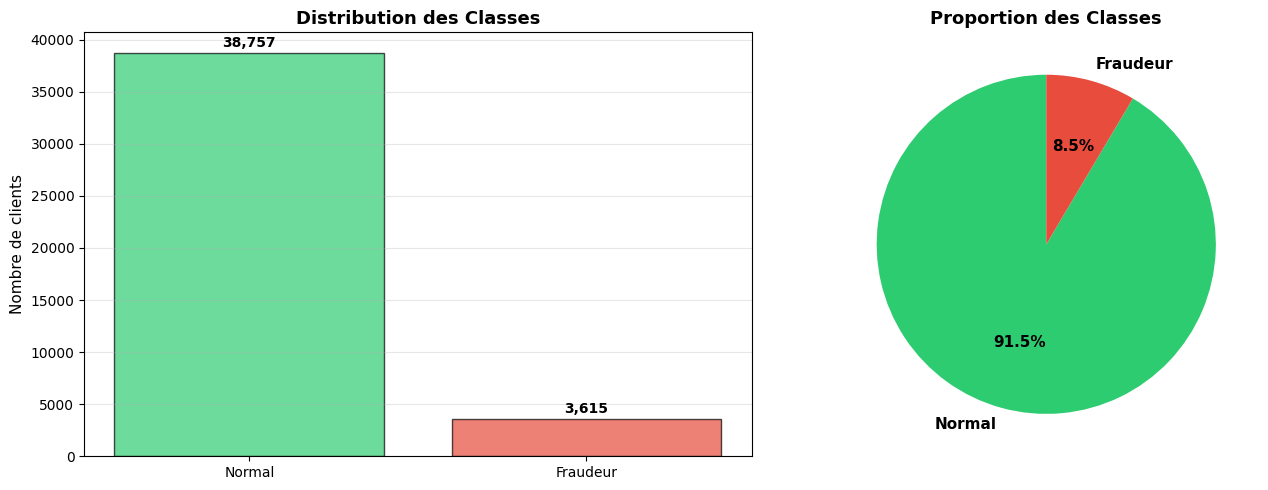

In [ ]:
# F) VISUALISATIONS
print("\n" + "="*70)
print("📊 GÉNÉRATION DES VISUALISATIONS")
print("="*70)

# Figure 1 : Distribution de FLAG
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Barplot
axes[0].bar(['Normal', 'Fraudeur'], flag_counts.values,
            color=['#2ecc71', '#e74c3c'], alpha=0.7, edgecolor='black')
axes[0].set_ylabel('Nombre de clients', fontsize=11)
axes[0].set_title('Distribution des Classes', fontsize=13, fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)
for i, v in enumerate(flag_counts.values):
    axes[0].text(i, v + 500, f'{v:,}', ha='center', fontsize=10, fontweight='bold')

# Pie chart
colors = ['#2ecc71', '#e74c3c']
axes[1].pie(flag_counts.values, labels=['Normal', 'Fraudeur'],
            autopct='%1.1f%%', colors=colors, startangle=90,
            textprops={'fontsize': 11, 'fontweight': 'bold'})
axes[1].set_title('Proportion des Classes', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()


📊 Génération de la matrice de corrélation...


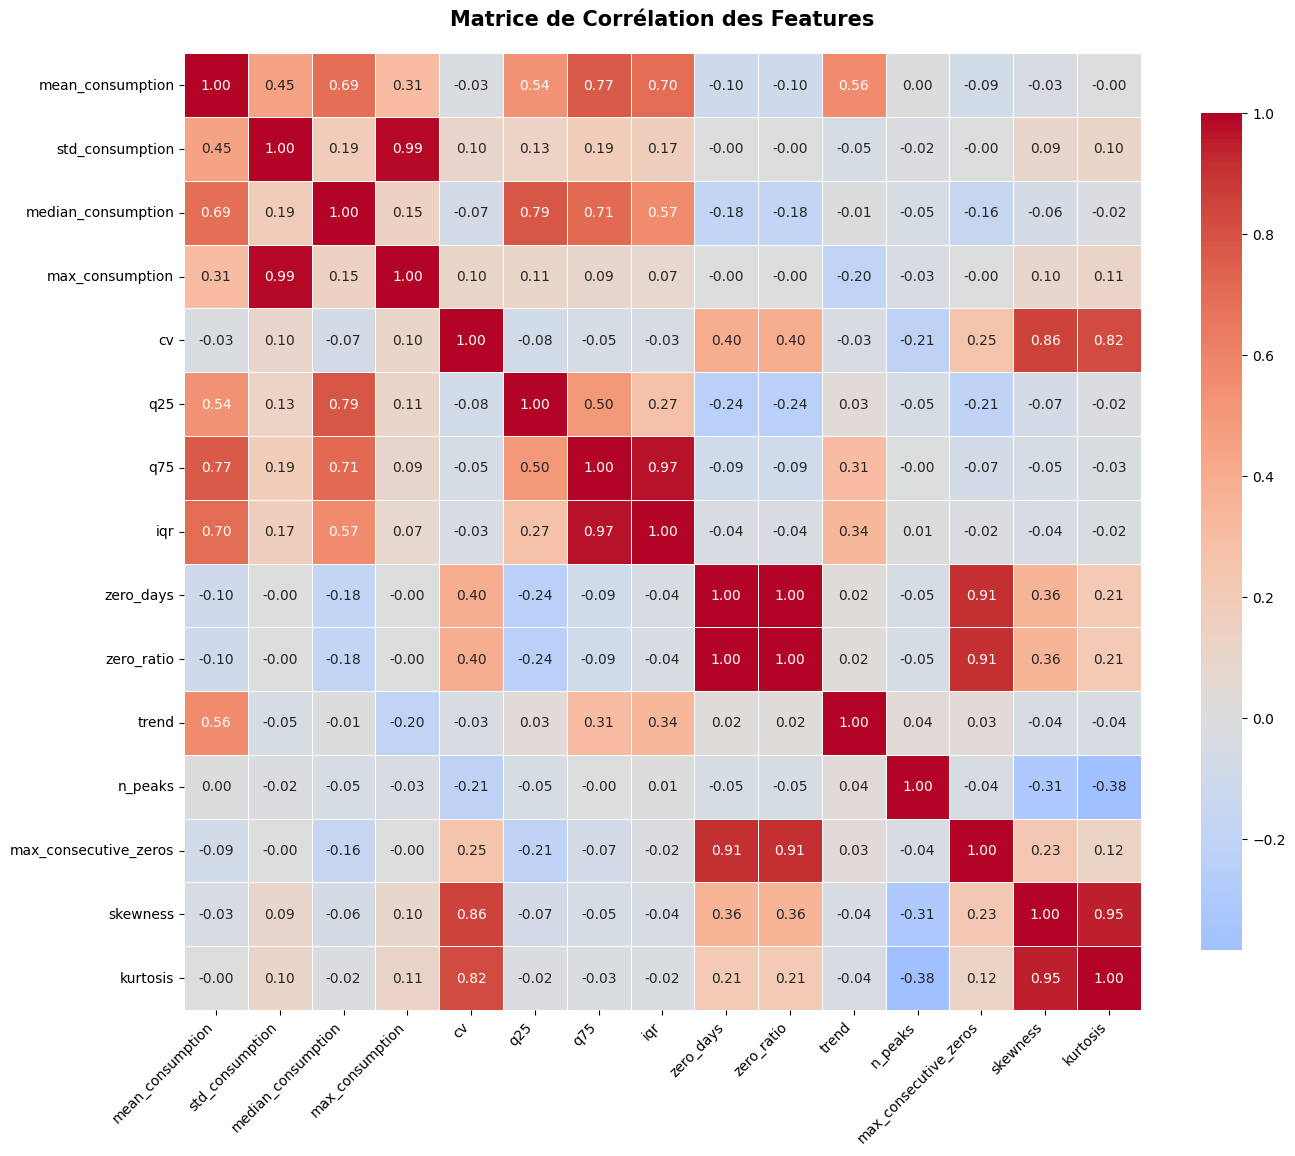

In [ ]:
# G) MATRICE DE CORRÉLATION
print("\n📊 Génération de la matrice de corrélation...")

# Sélectionner uniquement les features numériques (exclure CONS_NO et FLAG)
feature_cols = [col for col in df.columns if col not in ['CONS_NO', 'FLAG']]
df_features = df[feature_cols]

# Calculer la matrice de corrélation
correlation_matrix = df_features.corr()

# Visualisation
plt.figure(figsize=(14, 12))
sns.heatmap(correlation_matrix,
            annot=True,          # Afficher les valeurs
            fmt='.2f',           # Format 2 décimales
            cmap='coolwarm',     # Palette de couleurs
            center=0,            # Centrer à 0
            square=True,         # Carrés
            linewidths=0.5,      # Lignes de séparation
            cbar_kws={"shrink": 0.8})

plt.title('Matrice de Corrélation des Features', fontsize=15, fontweight='bold', pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:
# H) CORRÉLATIONS ÉLEVÉES (> 0.8)
print("\n" + "="*70)
print("🔍 CORRÉLATIONS ÉLEVÉES (|r| > 0.8)")
print("="*70)

# Extraire les paires de corrélation élevée
high_corr = []
for i in range(len(correlation_matrix.columns)):
    for j in range(i+1, len(correlation_matrix.columns)):
        if abs(correlation_matrix.iloc[i, j]) > 0.8:
            high_corr.append({
                'Feature 1': correlation_matrix.columns[i],
                'Feature 2': correlation_matrix.columns[j],
                'Corrélation': correlation_matrix.iloc[i, j]
            })

if len(high_corr) > 0:
    high_corr_df = pd.DataFrame(high_corr).sort_values('Corrélation',
                                                         key=abs,
                                                         ascending=False)
    print(high_corr_df.to_string(index=False))
else:
    print("✅ Aucune corrélation élevée détectée (> 0.8)")

print("\n" + "="*70)
print("✅ PARTIE 1 TERMINÉE !")
print("="*70)


🔍 CORRÉLATIONS ÉLEVÉES (|r| > 0.8)
      Feature 1             Feature 2  Corrélation
      zero_days            zero_ratio     1.000000
std_consumption       max_consumption     0.985249
            q75                   iqr     0.969162
       skewness              kurtosis     0.947734
      zero_days max_consecutive_zeros     0.907130
     zero_ratio max_consecutive_zeros     0.907130
             cv              skewness     0.858213
             cv              kurtosis     0.821501

✅ PARTIE 1 TERMINÉE !


##  Gestion des Valeurs Manquantes

In [ ]:
# 1️⃣ DÉTECTION DÉTAILLÉE DES NaN
# ----------------------------------------------------------------------------
print("="*70)
print("🔍 ANALYSE DÉTAILLÉE DES VALEURS MANQUANTES")
print("="*70)

# Colonnes avec NaN
nan_cols = df.columns[df.isnull().any()].tolist()
print(f"\n📊 Colonnes concernées : {nan_cols}")

# Analyser les clients avec NaN
df_with_nan = df[df['skewness'].isnull()]

print(f"\n⚠️ Nombre de clients avec NaN : {len(df_with_nan):,}")
print(f"   Pourcentage : {len(df_with_nan)/len(df)*100:.2f}%")


🔍 ANALYSE DÉTAILLÉE DES VALEURS MANQUANTES

📊 Colonnes concernées : ['skewness', 'kurtosis']

⚠️ Nombre de clients avec NaN : 2,114
   Pourcentage : 4.99%


In [ ]:
# 2️⃣ IMPUTATION
# ----------------------------------------------------------------------------
print("\n🔧 Stratégie d'imputation : Remplacement par 0")
print("   Raison : NaN = consommation constante (pas de variation)")

# Remplacer les NaN par 0
df['skewness'] = df['skewness'].fillna(0)
df['kurtosis'] = df['kurtosis'].fillna(0)



🔧 Stratégie d'imputation : Remplacement par 0
   Raison : NaN = consommation constante (pas de variation)


In [ ]:
# 3️⃣ VÉRIFICATION POST-IMPUTATION
# ----------------------------------------------------------------------------
print("\n✅ Après imputation :")
print(f"   skewness : {df['skewness'].isnull().sum()} NaN")
print(f"   kurtosis : {df['kurtosis'].isnull().sum()} NaN")

# Vérification globale
total_nan = df.isnull().sum().sum()
print(f"\n🎯 Total NaN dans le dataset : {total_nan}")

if total_nan == 0:
    print("✅ Aucune valeur manquante ! Dataset prêt.")
else:
    print(f"⚠️ Il reste {total_nan} valeurs manquantes.")

print("\n" + "="*70)
print("✅ PARTIE 2 TERMINÉE !")
print("="*70)


✅ Après imputation :
   skewness : 0 NaN
   kurtosis : 0 NaN

🎯 Total NaN dans le dataset : 0
✅ Aucune valeur manquante ! Dataset prêt.

✅ PARTIE 2 TERMINÉE !


## split X Y    train test




In [ ]:
# PARTIE 3 : SÉPARATION X/y & SPLIT TRAIN/TEST
# ============================================================================

from sklearn.model_selection import train_test_split

print("="*70)
print("✂️ PARTIE 3 : SÉPARATION X/y & SPLIT")
print("="*70)

# 1️⃣ SÉPARATION X (features) et y (target)
# ----------------------------------------------------------------------------
# Exclure CONS_NO (ID) et FLAG (target)
feature_cols = [col for col in df.columns if col not in ['CONS_NO', 'FLAG']]

X = df[feature_cols]
y = df['FLAG']

print(f"\n📊 Features (X) : {X.shape}")
print(f"   Colonnes : {list(X.columns)}")
print(f"\n🎯 Target (y)   : {y.shape}")
print(f"   Classes : {y.value_counts().to_dict()}")

✂️ PARTIE 3 : SÉPARATION X/y & SPLIT

📊 Features (X) : (42372, 15)
   Colonnes : ['mean_consumption', 'std_consumption', 'median_consumption', 'max_consumption', 'cv', 'q25', 'q75', 'iqr', 'zero_days', 'zero_ratio', 'trend', 'n_peaks', 'max_consecutive_zeros', 'skewness', 'kurtosis']

🎯 Target (y)   : (42372,)
   Classes : {0: 38757, 1: 3615}


In [ ]:
# 2️⃣ SPLIT TRAIN/TEST (80/20, stratifié)
# ----------------------------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,           # 20% pour test
    random_state=42,         # Reproductibilité
    stratify=y               # Même proportion de fraudeurs
)

print("\n" + "="*70)
print("✅ SPLIT EFFECTUÉ (80/20)")
print("="*70)

print(f"\n📦 Train Set :")
print(f"   X_train : {X_train.shape}")
print(f"   y_train : {y_train.shape}")
print(f"   Fraudeurs : {y_train.sum()} ({y_train.mean()*100:.2f}%)")

print(f"\n📦 Test Set :")
print(f"   X_test  : {X_test.shape}")
print(f"   y_test  : {y_test.shape}")
print(f"   Fraudeurs : {y_test.sum()} ({y_test.mean()*100:.2f}%)")

print("\n" + "="*70)
print("✅ PARTIE 3 TERMINÉE !")
print("="*70)


✅ SPLIT EFFECTUÉ (80/20)

📦 Train Set :
   X_train : (33897, 15)
   y_train : (33897,)
   Fraudeurs : 2892 (8.53%)

📦 Test Set :
   X_test  : (8475, 15)
   y_test  : (8475,)
   Fraudeurs : 723 (8.53%)

✅ PARTIE 3 TERMINÉE !


## NORMALISATION (STANDARDSCALER)

In [ ]:
from sklearn.preprocessing import StandardScaler

print("="*70)
print("📊 PARTIE 4 : NORMALISATION")
print("="*70)

# 1️⃣ CRÉATION DU SCALER
# ----------------------------------------------------------------------------
scaler = StandardScaler()

# 2️⃣ FIT sur Train + TRANSFORM sur Train et Test
# ----------------------------------------------------------------------------
print("\n🔧 Application de StandardScaler...")

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convertir en DataFrame (optionnel, pour garder les noms de colonnes)
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)


📊 PARTIE 4 : NORMALISATION

🔧 Application de StandardScaler...


In [ ]:
# 3️⃣ VÉRIFICATION
# ----------------------------------------------------------------------------
print("\n" + "="*70)
print("✅ NORMALISATION TERMINÉE")
print("="*70)

print(f"\n📦 X_train_scaled : {X_train_scaled.shape}")
print(f"   Moyenne : {X_train_scaled.mean().mean():.6f} (≈ 0)")
print(f"   Std     : {X_train_scaled.std().mean():.6f} (≈ 1)")

print(f"\n📦 X_test_scaled  : {X_test_scaled.shape}")
print(f"   Moyenne : {X_test_scaled.mean().mean():.6f}")
print(f"   Std     : {X_test_scaled.std().mean():.6f}")

# Afficher un exemple de transformation
print("\n📊 Exemple de transformation (première ligne) :")
print("\nAVANT (valeurs originales) :")
print(X_train.iloc[0])
print("\nAPRÈS (valeurs normalisées) :")
print(X_train_scaled.iloc[0])

print("\n" + "="*70)
print("✅ PARTIE 4 TERMINÉE !")
print("="*70)



✅ NORMALISATION TERMINÉE

📦 X_train_scaled : (33897, 15)
   Moyenne : -0.000000 (≈ 0)
   Std     : 1.000015 (≈ 1)

📦 X_test_scaled  : (8475, 15)
   Moyenne : 0.001205
   Std     : 0.769168

📊 Exemple de transformation (première ligne) :

AVANT (valeurs originales) :
mean_consumption          29.071847
std_consumption           18.486118
median_consumption        28.040000
max_consumption           73.300000
cv                         0.635877
q25                       20.300000
q75                       42.562500
iqr                       22.262500
zero_days                191.000000
zero_ratio                 0.184720
trend                      0.029032
n_peaks                   12.000000
max_consecutive_zeros    189.000000
skewness                  -0.019310
kurtosis                  -0.681234
Name: 34508, dtype: float64

APRÈS (valeurs normalisées) :
mean_consumption         0.617674
std_consumption          0.030926
median_consumption       1.016513
max_consumption         -0.0127

## Gestion du Déséquilibre

In [ ]:
# PARTIE 5 : GESTION DU DÉSÉQUILIBRE (3 MÉTHODES)
# ============================================================================

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.combine import SMOTEENN, SMOTETomek

print("="*70)
print("⚖️ PARTIE 5 : GESTION DU DÉSÉQUILIBRE")
print("="*70)

# État initial
print(f"\n📊 Dataset Train Original :")
print(f"   Total    : {len(y_train):,} clients")
print(f"   Normal   : {(y_train==0).sum():,} ({(y_train==0).sum()/len(y_train)*100:.2f}%)")
print(f"   Fraudeur : {(y_train==1).sum():,} ({(y_train==1).sum()/len(y_train)*100:.2f}%)")
print(f"   Ratio    : 1:{(y_train==0).sum()/(y_train==1).sum():.1f}")


⚖️ PARTIE 5 : GESTION DU DÉSÉQUILIBRE

📊 Dataset Train Original :
   Total    : 33,897 clients
   Normal   : 31,005 (91.47%)
   Fraudeur : 2,892 (8.53%)
   Ratio    : 1:10.7


In [ ]:

# ============================================================================
# 1️⃣ MÉTHODE 1 : SMOTE (Over-sampling)
# ============================================================================
print("\n" + "="*70)
print("1️⃣ SMOTE (Over-sampling)")
print("="*70)

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print(f"\n✅ Résultat SMOTE :")
print(f"   Total    : {len(y_train_smote):,} clients")
print(f"   Normal   : {(y_train_smote==0).sum():,} ({(y_train_smote==0).sum()/len(y_train_smote)*100:.2f}%)")
print(f"   Fraudeur : {(y_train_smote==1).sum():,} ({(y_train_smote==1).sum()/len(y_train_smote)*100:.2f}%)")
print(f"   Ratio    : 1:1 (Parfaitement équilibré)")


1️⃣ SMOTE (Over-sampling)

✅ Résultat SMOTE :
   Total    : 62,010 clients
   Normal   : 31,005 (50.00%)
   Fraudeur : 31,005 (50.00%)
   Ratio    : 1:1 (Parfaitement équilibré)


In [ ]:
# 2️⃣ MÉTHODE 2 : UNDERSAMPLING (Random)
# ============================================================================
print("\n" + "="*70)
print("2️⃣ UNDERSAMPLING (Random)")
print("="*70)

rus = RandomUnderSampler(random_state=42)
X_train_under, y_train_under = rus.fit_resample(X_train_scaled, y_train)

print(f"\n✅ Résultat Undersampling :")
print(f"   Total    : {len(y_train_under):,} clients")
print(f"   Normal   : {(y_train_under==0).sum():,} ({(y_train_under==0).sum()/len(y_train_under)*100:.2f}%)")
print(f"   Fraudeur : {(y_train_under==1).sum():,} ({(y_train_under==1).sum()/len(y_train_under)*100:.2f}%)")
print(f"   Ratio    : 1:1 (Parfaitement équilibré)")



2️⃣ UNDERSAMPLING (Random)

✅ Résultat Undersampling :
   Total    : 5,784 clients
   Normal   : 2,892 (50.00%)
   Fraudeur : 2,892 (50.00%)
   Ratio    : 1:1 (Parfaitement équilibré)


In [ ]:
# ============================================================================
# 3️⃣ MÉTHODE 3 : SMOTE-TOMEK (Hybrid)
# ============================================================================
print("\n" + "="*70)
print("3️⃣ SMOTE-TOMEK (Hybrid)")
print("="*70)

smote_tomek = SMOTETomek(random_state=42)
X_train_hybrid, y_train_hybrid = smote_tomek.fit_resample(X_train_scaled, y_train)

print(f"\n✅ Résultat SMOTE-Tomek :")
print(f"   Total    : {len(y_train_hybrid):,} clients")
print(f"   Normal   : {(y_train_hybrid==0).sum():,} ({(y_train_hybrid==0).sum()/len(y_train_hybrid)*100:.2f}%)")
print(f"   Fraudeur : {(y_train_hybrid==1).sum():,} ({(y_train_hybrid==1).sum()/len(y_train_hybrid)*100:.2f}%)")
print(f"   Ratio    : ~1:1")


3️⃣ SMOTE-TOMEK (Hybrid)

✅ Résultat SMOTE-Tomek :
   Total    : 61,274 clients
   Normal   : 30,637 (50.00%)
   Fraudeur : 30,637 (50.00%)
   Ratio    : ~1:1


In [ ]:
# ============================================================================
# 📊 COMPARAISON DES 3 MÉTHODES
# ============================================================================
print("\n" + "="*70)
print("📊 COMPARAISON DES 3 MÉTHODES")
print("="*70)

comparison = pd.DataFrame({
    'Méthode': ['Original', 'SMOTE', 'Undersampling', 'SMOTE-Tomek'],
    'Total': [
        len(y_train),
        len(y_train_smote),
        len(y_train_under),
        len(y_train_hybrid)
    ],
    'Normal': [
        (y_train==0).sum(),
        (y_train_smote==0).sum(),
        (y_train_under==0).sum(),
        (y_train_hybrid==0).sum()
    ],
    'Fraudeur': [
        (y_train==1).sum(),
        (y_train_smote==1).sum(),
        (y_train_under==1).sum(),
        (y_train_hybrid==1).sum()
    ]
})

comparison['Ratio'] = comparison['Normal'] / comparison['Fraudeur']
print("\n" + comparison.to_string(index=False))

print("\n" + "="*70)
print("✅ PARTIE 5 TERMINÉE ! 3 DATASETS CRÉÉS")
print("="*70)

# Résumé des datasets créés
print("\n📦 Datasets disponibles pour modélisation :")
print("   1. X_train_smote, y_train_smote       → SMOTE")
print("   2. X_train_under, y_train_under       → Undersampling")
print("   3. X_train_hybrid, y_train_hybrid     → SMOTE-Tomek")
print("   4. X_test_scaled, y_test              → Test (commun)")


📊 COMPARAISON DES 3 MÉTHODES

      Méthode  Total  Normal  Fraudeur     Ratio
     Original  33897   31005      2892 10.720954
        SMOTE  62010   31005     31005  1.000000
Undersampling   5784    2892      2892  1.000000
  SMOTE-Tomek  61274   30637     30637  1.000000

✅ PARTIE 5 TERMINÉE ! 3 DATASETS CRÉÉS

📦 Datasets disponibles pour modélisation :
   1. X_train_smote, y_train_smote       → SMOTE
   2. X_train_under, y_train_under       → Undersampling
   3. X_train_hybrid, y_train_hybrid     → SMOTE-Tomek
   4. X_test_scaled, y_test              → Test (commun)


## Entraînement des Modèles 🤖


In [ ]:
# PARTIE 6 : ENTRAÎNEMENT DES MODÈLES
# ============================================================================

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import time

print("="*70)
print("🤖 PARTIE 6 : ENTRAÎNEMENT DES MODÈLES")
print("="*70)

# ============================================================================
# DÉFINITION DES MODÈLES
# ============================================================================
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=100, random_state=42, eval_metric='logloss'),
    'LightGBM': LGBMClassifier(n_estimators=100, random_state=42, verbose=-1),
    'Neural Network': MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, random_state=42)
}


🤖 PARTIE 6 : ENTRAÎNEMENT DES MODÈLES


In [ ]:
# ============================================================================
# DATASETS À TESTER
# ============================================================================
datasets = {
    'SMOTE': (X_train_smote, y_train_smote),
    'Undersampling': (X_train_under, y_train_under),
    'SMOTE-Tomek': (X_train_hybrid, y_train_hybrid)
}

# ============================================================================
# DICTIONNAIRE POUR STOCKER LES RÉSULTATS
# ============================================================================
results = []


In [ ]:
# ============================================================================
# BOUCLE D'ENTRAÎNEMENT : 3 DATASETS × 5 MODÈLES = 15 COMBINAISONS
# ============================================================================
print("\n🚀 Début de l'entraînement...")
print("="*70)

for dataset_name, (X_train_data, y_train_data) in datasets.items():

    print(f"\n{'='*70}")
    print(f"📊 DATASET : {dataset_name}")
    print(f"   Taille : {len(y_train_data):,} clients")
    print(f"{'='*70}")

    for model_name, model in models.items():

        print(f"\n   🔹 {model_name}... ", end='')

        # Chronométrer l'entraînement
        start_time = time.time()

        # Entraînement
        model.fit(X_train_data, y_train_data)

        # Prédiction sur le test set
        y_pred = model.predict(X_test_scaled)
        y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]

        # Calcul du temps
        train_time = time.time() - start_time

        # Métriques
        cm = confusion_matrix(y_test, y_pred)
        tn, fp, fn, tp = cm.ravel()

        accuracy = (tp + tn) / (tp + tn + fp + fn)
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0
        f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
        auc = roc_auc_score(y_test, y_pred_proba)

        # Stocker les résultats
        results.append({
            'Dataset': dataset_name,
            'Model': model_name,
            'Accuracy': accuracy,
            'Precision': precision,
            'Recall': recall,
            'F1-Score': f1,
            'AUC': auc,
            'Time (s)': train_time,
            'TP': tp,
            'TN': tn,
            'FP': fp,
            'FN': fn
        })

        print(f"✅ (Recall: {recall:.3f}, F1: {f1:.3f}, AUC: {auc:.3f})")

print("\n" + "="*70)
print("✅ ENTRAÎNEMENT TERMINÉ ! 15 MODÈLES TESTÉS")
print("="*70)


🚀 Début de l'entraînement...

📊 DATASET : SMOTE
   Taille : 62,010 clients

   🔹 Logistic Regression... ✅ (Recall: 0.599, F1: 0.252, AUC: 0.719)

   🔹 Random Forest... ✅ (Recall: 0.419, F1: 0.328, AUC: 0.766)

   🔹 XGBoost... ✅ (Recall: 0.483, F1: 0.335, AUC: 0.772)

   🔹 LightGBM... ✅ (Recall: 0.564, F1: 0.349, AUC: 0.783)

   🔹 Neural Network... ✅ (Recall: 0.584, F1: 0.251, AUC: 0.721)

📊 DATASET : Undersampling
   Taille : 5,784 clients

   🔹 Logistic Regression... ✅ (Recall: 0.607, F1: 0.224, AUC: 0.697)

   🔹 Random Forest... ✅ (Recall: 0.705, F1: 0.272, AUC: 0.758)

   🔹 XGBoost... ✅ (Recall: 0.703, F1: 0.267, AUC: 0.762)

   🔹 LightGBM... ✅ (Recall: 0.716, F1: 0.278, AUC: 0.780)

   🔹 Neural Network... ✅ (Recall: 0.674, F1: 0.275, AUC: 0.763)

📊 DATASET : SMOTE-Tomek
   Taille : 61,274 clients

   🔹 Logistic Regression... ✅ (Recall: 0.595, F1: 0.252, AUC: 0.719)

   🔹 Random Forest... ✅ (Recall: 0.414, F1: 0.322, AUC: 0.763)

   🔹 XGBoost... ✅ (Recall: 0.494, F1: 0.340, AUC: 0.

In [ ]:
# TABLEAU RÉCAPITULATIF
# ============================================================================
results_df = pd.DataFrame(results)

print("\n📊 RÉSULTATS COMPLETS :")
print("="*70)
print(results_df[['Dataset', 'Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC']].to_string(index=False))

# ============================================================================
# TOP 5 MODÈLES (Classés par Recall)
# ============================================================================
print("\n" + "="*70)
print("🏆 TOP 5 MODÈLES (Classés par Recall sur Fraudeurs)")
print("="*70)

top5 = results_df.nlargest(5, 'Recall')[['Dataset', 'Model', 'Recall', 'F1-Score', 'AUC']]
print(top5.to_string(index=False))


📊 RÉSULTATS COMPLETS :
      Dataset               Model  Accuracy  Precision   Recall  F1-Score      AUC
        SMOTE Logistic Regression  0.696047   0.159250 0.598893  0.251598 0.718798
        SMOTE       Random Forest  0.853569   0.269573 0.419087  0.328100 0.765644
        SMOTE             XGBoost  0.836814   0.256996 0.482711  0.335416 0.771998
        SMOTE            LightGBM  0.820649   0.252945 0.564315  0.349315 0.783363
        SMOTE      Neural Network  0.703127   0.160030 0.583679  0.251190 0.721104
Undersampling Logistic Regression  0.640354   0.137059 0.607192  0.223637 0.697109
Undersampling       Random Forest  0.677404   0.168261 0.705394  0.271710 0.757642
Undersampling             XGBoost  0.670678   0.164721 0.702628  0.266877 0.762014
Undersampling            LightGBM  0.683186   0.172782 0.716459  0.278420 0.779809
Undersampling      Neural Network  0.696401   0.172450 0.673582  0.274598 0.762905
  SMOTE-Tomek Logistic Regression  0.698997   0.159970 0.594744

In [ ]:
# MEILLEUR MODÈLE
# ============================================================================
best_model_idx = results_df['Recall'].idxmax()
best_result = results_df.loc[best_model_idx]

print("\n" + "="*70)
print("🥇 MEILLEUR MODÈLE")
print("="*70)
print(f"   Dataset  : {best_result['Dataset']}")
print(f"   Modèle   : {best_result['Model']}")
print(f"   Recall   : {best_result['Recall']:.3f} ⭐")
print(f"   F1-Score : {best_result['F1-Score']:.3f}")
print(f"   AUC      : {best_result['AUC']:.3f}")
print(f"   Accuracy : {best_result['Accuracy']:.3f}")

print("\n" + "="*70)
print("✅ PARTIE 6 TERMINÉE !")
print("="*70)


🥇 MEILLEUR MODÈLE
   Dataset  : Undersampling
   Modèle   : LightGBM
   Recall   : 0.716 ⭐
   F1-Score : 0.278
   AUC      : 0.780
   Accuracy : 0.683

✅ PARTIE 6 TERMINÉE !


##  ANALYSE APPROFONDIE DU MEILLEUR MODÈLE

In [ ]:
# ============================================================================
# PARTIE 7A : ANALYSE APPROFONDIE DU MEILLEUR MODÈLE
# ============================================================================

from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

print("="*70)
print("📊 PARTIE 7A : ANALYSE APPROFONDIE")
print("="*70)
# ============================================================================
# 1️⃣ RÉ-ENTRAÎNER LE MEILLEUR MODÈLE
# ============================================================================
print("\n🔧 Ré-entraînement du meilleur modèle...")

best_model = LGBMClassifier(n_estimators=100, random_state=42, verbose=-1)
best_model.fit(X_train_under, y_train_under)

y_pred = best_model.predict(X_test_scaled)
y_pred_proba = best_model.predict_proba(X_test_scaled)[:, 1]

print("✅ Modèle : Undersampling + LightGBM")

📊 PARTIE 7A : ANALYSE APPROFONDIE

🔧 Ré-entraînement du meilleur modèle...
✅ Modèle : Undersampling + LightGBM



📊 MATRICE DE CONFUSION

   Vrais Négatifs (TN)  : 5,272 (Normaux bien classés)
   Faux Positifs (FP)   : 2,480 (Normaux détectés comme fraudeurs)
   Faux Négatifs (FN)   : 205 (Fraudeurs manqués) ⚠️
   Vrais Positifs (TP)  : 518 (Fraudeurs détectés) ✅


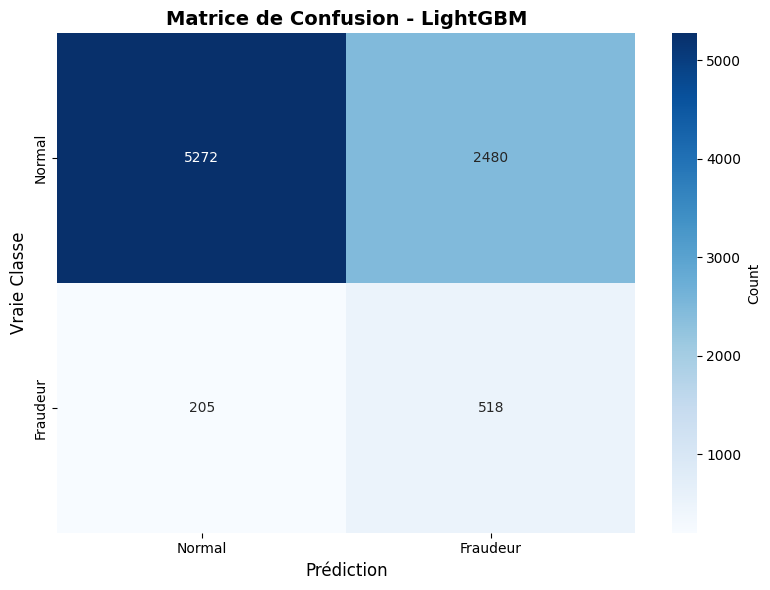

In [ ]:
# ============================================================================
# 2️⃣ MATRICE DE CONFUSION DÉTAILLÉE
# ============================================================================
print("\n" + "="*70)
print("📊 MATRICE DE CONFUSION")
print("="*70)

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print(f"\n   Vrais Négatifs (TN)  : {tn:,} (Normaux bien classés)")
print(f"   Faux Positifs (FP)   : {fp:,} (Normaux détectés comme fraudeurs)")
print(f"   Faux Négatifs (FN)   : {fn:,} (Fraudeurs manqués) ⚠️")
print(f"   Vrais Positifs (TP)  : {tp:,} (Fraudeurs détectés) ✅")

# Visualisation
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal', 'Fraudeur'],
            yticklabels=['Normal', 'Fraudeur'],
            cbar_kws={'label': 'Count'})
plt.title('Matrice de Confusion - LightGBM', fontsize=14, fontweight='bold')
plt.ylabel('Vraie Classe', fontsize=12)
plt.xlabel('Prédiction', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
# Métriques détaillées
print(f"\n   Recall (Fraudeurs)   : {tp/(tp+fn):.3f} ({tp}/{tp+fn})")
print(f"   Precision (Fraudeurs): {tp/(tp+fp):.3f} ({tp}/{tp+fp})")
print(f"   Specificity (Normaux): {tn/(tn+fp):.3f} ({tn}/{tn+fp})")


   Recall (Fraudeurs)   : 0.716 (518/723)
   Precision (Fraudeurs): 0.173 (518/2998)
   Specificity (Normaux): 0.680 (5272/7752)



📈 COURBE ROC


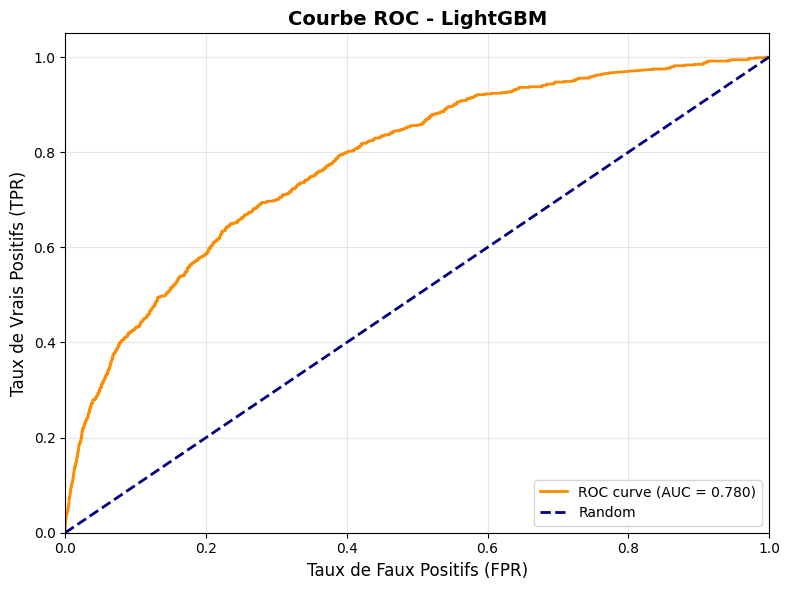

✅ AUC Score : 0.780


In [ ]:
# ============================================================================
# 3️⃣ COURBE ROC
# ============================================================================
print("\n" + "="*70)
print("📈 COURBE ROC")
print("="*70)

fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
auc = roc_auc_score(y_test, y_pred_proba)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taux de Faux Positifs (FPR)', fontsize=12)
plt.ylabel('Taux de Vrais Positifs (TPR)', fontsize=12)
plt.title('Courbe ROC - LightGBM', fontsize=14, fontweight='bold')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"✅ AUC Score : {auc:.3f}")


🔍 IMPORTANCE DES FEATURES

              Feature  Importance
max_consecutive_zeros         374
                trend         300
            zero_days         289
      max_consumption         249
              n_peaks         248
             kurtosis         244
                   cv         235
             skewness         206
      std_consumption         201
     mean_consumption         140
   median_consumption         139
                  q25         135
                  q75         120
                  iqr         120
           zero_ratio           0


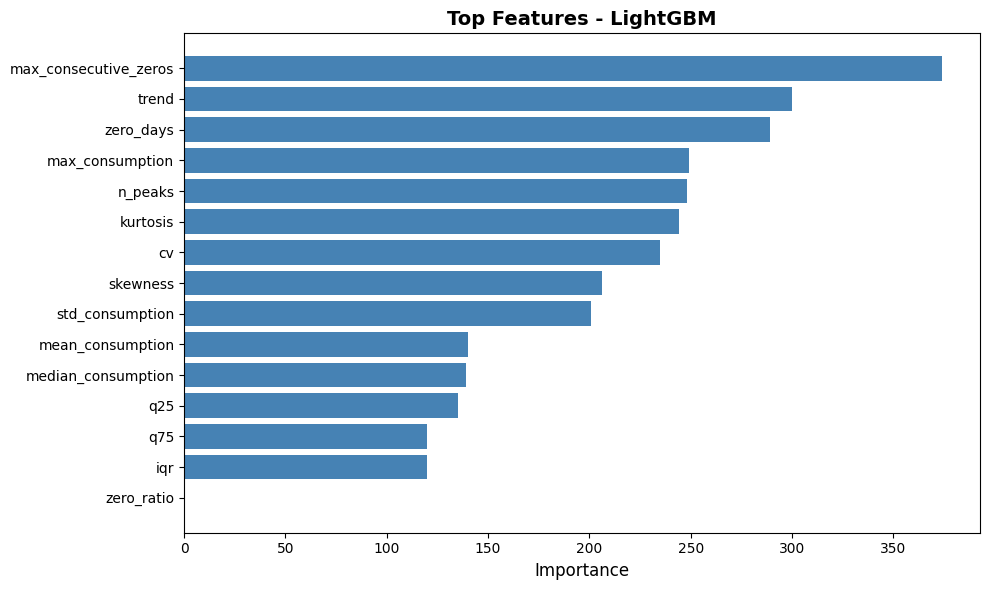

In [ ]:
# 4️⃣ FEATURE IMPORTANCE
# ============================================================================
print("\n" + "="*70)
print("🔍 IMPORTANCE DES FEATURES")
print("="*70)

# Récupérer les importances
feature_importance = pd.DataFrame({
    'Feature': X_train_under.columns,
    'Importance': best_model.feature_importances_
}).sort_values('Importance', ascending=False)

print("\n" + feature_importance.to_string(index=False))

# Visualisation
plt.figure(figsize=(10, 6))
plt.barh(feature_importance['Feature'], feature_importance['Importance'], color='steelblue')
plt.xlabel('Importance', fontsize=12)
plt.title('Top Features - LightGBM', fontsize=14, fontweight='bold')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================================
# 5️⃣ SEUIL DE DÉCISION OPTIMAL
# ============================================================================
print("\n" + "="*70)
print("🎯 RECHERCHE DU SEUIL OPTIMAL")
print("="*70)
# Tester différents seuils
thresholds_to_test = [0.3, 0.4, 0.5, 0.6, 0.7]
threshold_results = []

for threshold in thresholds_to_test:
    y_pred_thresh = (y_pred_proba >= threshold).astype(int)
    cm = confusion_matrix(y_test, y_pred_thresh)
    tn, fp, fn, tp = cm.ravel()

    recall = tp / (tp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

    threshold_results.append({
        'Seuil': threshold,
        'Recall': recall,
        'Precision': precision,
        'F1-Score': f1,
        'TP': tp,
        'FP': fp,
        'FN': fn
    })

threshold_df = pd.DataFrame(threshold_results)
print("\n" + threshold_df.to_string(index=False))

# Meilleur seuil pour Recall
best_threshold = threshold_df.loc[threshold_df['Recall'].idxmax(), 'Seuil']
print(f"\n🏆 Meilleur seuil pour maximiser Recall : {best_threshold}")

print("\n" + "="*70)
print("✅ PARTIE 7A TERMINÉE !")
print("="*70)




🎯 RECHERCHE DU SEUIL OPTIMAL

 Seuil   Recall  Precision  F1-Score  TP   FP  FN
   0.3 0.908714   0.129714  0.227021 657 4408  66
   0.4 0.829876   0.148075  0.251309 600 3452 123
   0.5 0.716459   0.172782  0.278420 518 2480 205
   0.6 0.587828   0.213568  0.313306 425 1565 298
   0.7 0.449516   0.272880  0.339603 325  866 398

🏆 Meilleur seuil pour maximiser Recall : 0.3

✅ PARTIE 7A TERMINÉE !


## OPTIMISATION (GRID SEARCH)

In [ ]:
from sklearn.model_selection import GridSearchCV

print("\n" + "="*70)
print("⚙️ PARTIE 7B : OPTIMISATION DES HYPERPARAMÈTRES")
print("="*70)

# Grille de paramètres
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 10, 15],
    'learning_rate': [0.05, 0.1, 0.2],
    'num_leaves': [31, 50, 70]
}

print("\n🔧 Grid Search en cours...")
print(f"   Combinaisons à tester : {len(param_grid['n_estimators']) * len(param_grid['max_depth']) * len(param_grid['learning_rate']) * len(param_grid['num_leaves'])}")


⚙️ PARTIE 7B : OPTIMISATION DES HYPERPARAMÈTRES

🔧 Grid Search en cours...
   Combinaisons à tester : 81


In [ ]:
# Grid Search (scoring=recall pour maximiser la détection)
grid_search = GridSearchCV(
    LGBMClassifier(random_state=42, verbose=-1),
    param_grid,
    cv=3,
    scoring='recall',  # Optimiser pour Recall
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_under, y_train_under)

print("\n✅ Grid Search terminé !")

# Meilleurs paramètres
print("\n" + "="*70)
print("🏆 MEILLEURS PARAMÈTRES")
print("="*70)
print(f"\n{grid_search.best_params_}")

Fitting 3 folds for each of 81 candidates, totalling 243 fits

✅ Grid Search terminé !

🏆 MEILLEURS PARAMÈTRES

{'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 100, 'num_leaves': 31}


In [ ]:
# Évaluer le modèle optimisé
best_model_optimized = grid_search.best_estimator_
y_pred_opt = best_model_optimized.predict(X_test_scaled)
y_pred_proba_opt = best_model_optimized.predict_proba(X_test_scaled)[:, 1]

# Métriques
cm_opt = confusion_matrix(y_test, y_pred_opt)
tn, fp, fn, tp = cm_opt.ravel()

recall_opt = tp / (tp + fn)
precision_opt = tp / (tp + fp) if (tp + fp) > 0 else 0
f1_opt = 2 * (precision_opt * recall_opt) / (precision_opt + recall_opt) if (precision_opt + recall_opt) > 0 else 0
auc_opt = roc_auc_score(y_test, y_pred_proba_opt)

print("\n" + "="*70)
print("📊 COMPARAISON AVANT/APRÈS OPTIMISATION")
print("="*70)

comparison = pd.DataFrame({
    'Modèle': ['Avant (défaut)', 'Après (optimisé)'],
    'Recall': [tp/(tp+fn), recall_opt],
    'Precision': [tp/(tp+fp), precision_opt],
    'F1-Score': [(tp/(tp+fp)) / ((tp/(tp+fp)) + (tp/(tp+fn))), f1_opt],
    'AUC': [auc, auc_opt]
})

print("\n" + comparison.to_string(index=False))

# Amélioration
improvement = (recall_opt - tp/(tp+fn)) / (tp/(tp+fn)) * 100
print(f"\n📈 Amélioration du Recall : {improvement:+.2f}%")

print("\n" + "="*70)
print("✅ PARTIE 7B TERMINÉE !")
print("="*70)


📊 COMPARAISON AVANT/APRÈS OPTIMISATION

          Modèle   Recall  Precision  F1-Score      AUC
  Avant (défaut) 0.755187   0.168831  0.182714 0.779809
Après (optimisé) 0.755187   0.168831  0.275967 0.779545

📈 Amélioration du Recall : +0.00%

✅ PARTIE 7B TERMINÉE !


## Sauvegarde du Modèle Final

In [ ]:

import joblib
import os

print("="*70)
print("💾 SAUVEGARDE DU MODÈLE FINAL")
print("="*70)

# Créer le dossier 'models'
os.makedirs('models', exist_ok=True)

# Sauvegarder modèle + scaler
joblib.dump(best_model, 'models/fraud_detection_model.pkl')
joblib.dump(scaler, 'models/scaler.pkl')

print("\n✅ Fichiers sauvegardés :")
print("   → models/fraud_detection_model.pkl")
print("   → models/scaler.pkl")

💾 SAUVEGARDE DU MODÈLE FINAL

✅ Fichiers sauvegardés :
   → models/fraud_detection_model.pkl
   → models/scaler.pkl


In [ ]:
# =====================================================================
# 🚀 TEST DE PRÉDICTION - COMPARAISON DES 3 MODÈLES
# =====================================================================
import joblib
import pandas as pd

print("="*70)
print("🚀 TEST DE PRÉDICTION ET COMPARAISON DES 3 MODÈLES")
print("="*70)

# ============================================================
# 1️⃣ Charger les modèles et scalers
# ============================================================
models_info = {
    "Fraud Detection (Défaut)": {
        "model": joblib.load("models/fraud_detection_model.pkl"),
        "scaler": joblib.load("models/scaler.pkl")
    },
    "XGBoost (Optimisé)": {
        "model": joblib.load("models/best_xgboost_model.pkl"),
        "scaler": joblib.load("models/scaler2.pkl")
    },
    "LightGBM (Optimisé)": {
        "model": joblib.load("models/best_lightgbm_model.pkl"),
        "scaler": joblib.load("models/scaler2.pkl")
    }
}

# ============================================================
# 2️⃣ Sélectionner un échantillon de test
# ============================================================
sample = X_test.head(5)
true_labels = y_test.head(5).values

# ============================================================
# 3️⃣ Prédire et afficher les résultats pour chaque modèle
# ============================================================
for name, assets in models_info.items():
    model = assets["model"]
    scaler = assets["scaler"]

    sample_scaled = scaler.transform(sample)
    preds = model.predict(sample_scaled)
    probas = model.predict_proba(sample_scaled)[:, 1]

    results = pd.DataFrame({
        'Probabilité': probas,
        'Prédiction': ['Fraudeur' if p == 1 else 'Normal' for p in preds],
        'Réalité': ['Fraudeur' if y == 1 else 'Normal' for y in true_labels]
    })

    print(f"\n🧠 Résultats pour le modèle : {name}")
    print(results.to_string(index=False))
    print("-" * 70)

print("\n✅ COMPARAISON TERMINÉE ! Les trois modèles ont été testés avec succès.")
print("="*70)


🚀 TEST DE PRÉDICTION ET COMPARAISON DES 3 MODÈLES

🧠 Résultats pour le modèle : Fraud Detection (Défaut)
 Probabilité Prédiction  Réalité
    0.947212   Fraudeur Fraudeur
    0.620591   Fraudeur   Normal
    0.664764   Fraudeur Fraudeur
    0.212382     Normal   Normal
    0.562484   Fraudeur   Normal
----------------------------------------------------------------------

🧠 Résultats pour le modèle : XGBoost (Optimisé)
 Probabilité Prédiction  Réalité
    0.070440     Normal Fraudeur
    0.197947     Normal   Normal
    0.216071     Normal Fraudeur
    0.024301     Normal   Normal
    0.257882     Normal   Normal
----------------------------------------------------------------------

🧠 Résultats pour le modèle : LightGBM (Optimisé)
 Probabilité Prédiction  Réalité
    0.005886     Normal Fraudeur
    0.051433     Normal   Normal
    0.481861     Normal Fraudeur
    0.004532     Normal   Normal
    0.120438     Normal   Normal
------------------------------------------------------------